# Тематическое моделирование с использованием трансформеров (Grand Finale!)

На этом занятии мы с вами будем использовать материал нескольких разделов дисциплин "Обработка естественного языка" и "Машинное обучение". Рассмотрим современный подход к тематическому моделированию с использованием трансформеров.

Задача тематического моделирования заключается в построении тематических профилей документов некоторой коллекции текстовых документов с последующей интерпретацией тем. Можем попробовать решить задачу "в лоб" - **выполнить кластеризацию текстовых документов, после чего попытаться интерпретировать каждый кластер**.

Кластеризация текстовых документов - это кластеризация эмбеддингов пониженной размерности. Получать эмбеддинги, понижать размерность и производить кластеризацию мы с вами умеем.

Работать будем с набором данных из Лабораторной работы 5.

Начинаем как обычно с загрузки и предварительной обработки текстовых данных.

## Загрузка и предварительная обработка текстовых данных

In [ ]:
import pandas as pd

In [ ]:
data = pd.read_parquet('0000.parquet', 'pyarrow')
data

,text,summary,topic,url,title,date
0,Сладострастник в течение трех лет преследовал ...,Старший преподаватель института коммунального ...,incident,https://www.mk.ru/incident/article/2010/01/05/...,Педофил преследовал подростка три года,06/01/2010
1,Буквально за час до боя курантов в подземном п...,Манежная площадь Москвы стала местом последнег...,incident,https://www.mk.ru/incident/article/2010/01/05/...,Таджики устроили резню на Манежной площади под...,06/01/2010
2,"Там они покатались на лыжах и снегоходах, пооб...",Президент РФ Дмитрий Медведев с семьей проводи...,politics,https://www.mk.ru/politics/article/2010/01/05/...,"""""""За все платит президент""""""",06/01/2010
3,Сосед расстрелял соседа из-за претензий по пов...,Первое убийство в 2010 году произошло в Москве...,incident,https://www.mk.ru/incident/article/2010/01/05/...,Первое убийство года спровоцировал потоп,06/01/2010
4,Причиной трагедии специалисты считают нарушени...,"Шесть человек, в том числе 9-летний ребенок, з...",incident,https://www.mk.ru/incident/article/2010/01/05/...,Целая семья не пережила газовой атаки,06/01/2010
...,...,...,...,...,...,...
25551,"— Георгий Евгеньевич, складывается впечатление...",Они чувствуют себя чужими в мире взрослых и тя...,social,https://www.mk.ru/social/2013/03/19/828147-kak...,Как не стать педофилом?,20/03/2013
25552,"Открывая заседание, президент ассоциации Валер...",К такому выводу пришли представители малых и с...,mosobl,https://www.mk.ru/mosobl/2013/03/19/828148-ray...,Райсовет — на обочине,20/03/2013
25553,На улице Марины Цветаевой и на соседней Спарта...,Власти Подмосковья в лице врио губернатора Анд...,mosobl,https://www.mk.ru/mosobl/2013/03/19/828197-po-...,По закону против джунглей,20/03/2013
25554,Что не нравится жителям города? В последние го...,В Клину строительство высотки в исторической ч...,mosobl,https://www.mk.ru/mosobl/2013/03/19/828203-mes...,Местный батюшка получил место в торговых рядах,20/03/2013


Будем использовать Spacy

In [ ]:
import spacy

Нам будет достаточно самой базовой модели, поскольку мы не будем проводить векторизацию (простите, Александр)

In [ ]:
! spacy download ru_core_news_sm -q

2023-11-17 21:16:39.116200: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2023-11-17 21:16:39.116260: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2023-11-17 21:16:39.116291: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2023-11-17 21:16:40.759309: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.3/15.3 MB 61.1 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('ru_core_news_sm')


In [ ]:
spacy_model = spacy.load('ru_core_news_sm')

In [ ]:
import re
import string

In [ ]:
def preprocess(text: str) -> str:
    pattern = re.compile(r'[^а-я]+')
    text = text.lower()
    text = pattern.sub(' ', text).strip()

    doc = spacy_model(text)
    tokens = [token.lemma_ for token in doc if token.lemma_ not in spacy_model.Defaults.stop_words]
    tokens = [token for token in tokens if token not in string.punctuation]
    tokens = [token for token in tokens if len(token) > 2]

    text= ' '.join(tokens)

    return text

In [ ]:
texts = data['text'].values[:2000]

In [ ]:
from tqdm.auto import tqdm

In [ ]:
docs = [preprocess(text) for text in tqdm(texts)]

  0%|          | 0/2000 [00:00<?, ?it/s]

In [ ]:
len(docs), docs[0]

(2000,
 'сладострастник течение три год преследовать подросток надежда совратить сообщить следственный отдел хорошевский район прокуратура москва август год летний павел вместе друг отдыхать берег москва река крылатский мост ребятам подойти мужчина новый знакомый представиться евгением предложить вместе пообедать ресторан быстрый питание искупаться берег педагог начать приставать мальчик школьник убежать педофил успеть снять голый подросток мобильный телефон жизнь мальчик превратиться сущий евгений узнать жить павел шантажировать кошмар продолжаться три год преподаватель угрожать показать фотография друг знакомым павла негодяй исписать непотребный надпись стена подъезд проживать друг школьник день приехать сергиев посад бабушка мальчик накинуться школьник нож отчаяться подросток рассказать обо мать обратиться милиция первый раз страж порядок упустить летний педофил слово развести милиционер нагрянуть квартира евгений предлог прощание мама инвалид зайти соседний комната выпрыгнуть окно 

## Кластеризация текстовых документов

Первым делом нужно получить эмбеддингги документов - применим Sentence Transformers.

In [ ]:
! pip install -U sentence-transformers -q

In [ ]:
from sentence_transformers import SentenceTransformer

Возьмем модель, с которой ранее работали.

In [ ]:
embedding_model = SentenceTransformer('distiluse-base-multilingual-cased-v1')

In [ ]:
doc_embeddings = embedding_model.encode(docs, convert_to_tensor=True)

In [ ]:
doc_embeddings.shape

torch.Size([2000, 512])

Нормируем эмбеддинги

In [ ]:
from sentence_transformers import util

In [ ]:
doc_embeddings = util.normalize_embeddings(doc_embeddings)

In [ ]:
doc_embeddings.shape

torch.Size([2000, 512])

In [ ]:
doc_embeddings = doc_embeddings.numpy()

In [ ]:
doc_embeddings.shape

(2000, 512)

Можно приступать к кластеризации, однако мы с вами помним про "проклятие размерностей". Давайте попробуем применить PCA для понижения размерности.

In [ ]:
from sklearn.decomposition import PCA

In [ ]:
pca = PCA(n_components=2)

In [ ]:
pca.fit(doc_embeddings)

PCA(n_components=2)

In [ ]:
sum(pca.explained_variance_ratio_)

0.07743922993540764

Смех, да и только! Но не отчаиваемся.

При понижении размерности эмбеддингов текстовых документов обычно применяются более продвинутые техники понижения размерности (например, t-SNE). Мы будем использовать самый модный алгоритм - [UMAP (Uniform Manifold Approximation and Projection)](https://ru.wikipedia.org/wiki/UMAP).

In [ ]:
! pip install umap-learn -q

In [ ]:
from umap import UMAP

In [ ]:
u = UMAP(n_components=2, n_neighbors=10).fit(doc_embeddings)
doc_embeddings_umap = u.transform(doc_embeddings)

In [ ]:
import matplotlib.pyplot as plt

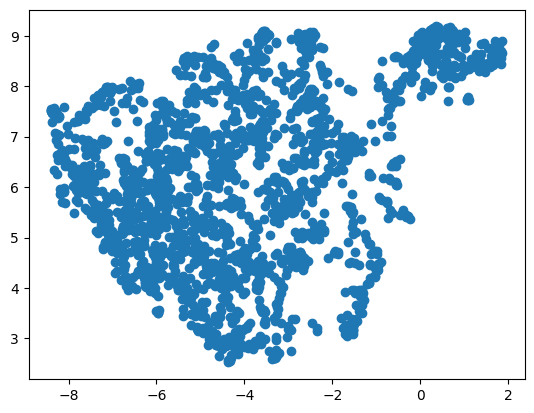

In [ ]:
plt.scatter(doc_embeddings_umap[:,0], doc_embeddings_umap[:,1]);

Применим алгоритм DBSCAN.

In [ ]:
from sklearn.cluster import DBSCAN
import numpy as np

[-1  0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22
 23 24]


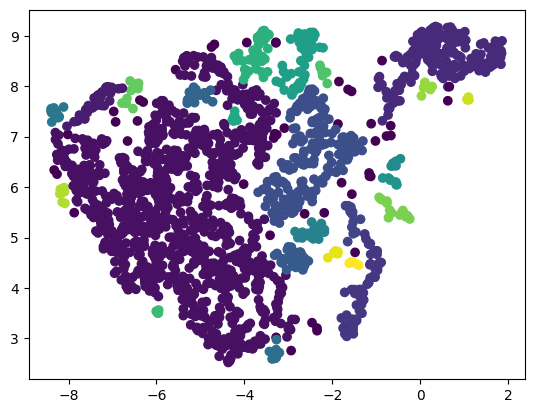

In [ ]:
dbscan = DBSCAN(min_samples=4, eps=0.2).fit(doc_embeddings_umap)
print(np.unique(dbscan.labels_))
plt.scatter(doc_embeddings_umap[:,0], doc_embeddings_umap[:,1], c=dbscan.labels_);

## Интерпретация тем

Давайте соберем датафрейм.

In [ ]:
df = pd.DataFrame(data = {
    'doc': docs,
    'topic': dbscan.labels_
})

In [ ]:
df

,doc,topic
0,сладострастник течение три год преследовать по...,0
1,буквально час бой курант подземный переход ста...,1
2,покататься лыжа снегоход пообщаться отдыхать п...,2
3,сосед расстрелять сосед претензия повод затопл...,0
4,причина трагедия специалист считать нарушение ...,0
...,...,...
1995,скачка закончиться безусловный победитель выяв...,0
1996,сводный оркестр белый кость военный духов музы...,5
1997,горький правда знать междуреченск знать причин...,0
1998,май президент медведев поставить подпись закон...,15


Давайте объединим все документы в рамках каждого класса в один большой документ.

In [ ]:
docs_per_class = df.groupby(['topic'], as_index=False).agg({'doc': ' '.join})

In [ ]:
docs_per_class

,topic,doc
0,-1,четверо новичок альпинист инструктор андрей ли...
1,0,сладострастник течение три год преследовать по...
2,1,буквально час бой курант подземный переход ста...
3,2,покататься лыжа снегоход пообщаться отдыхать п...
4,3,исследование специалист смочь съесть сообщить ...
5,4,излюбленный место прогулка временно закрыть по...
6,5,район построить центр культура искусство извес...
7,6,восемь год бытность президент владимир путин о...
8,7,принимать работа сюда россиянин возраст год из...
9,8,обратить внимание уникальный свойство лианы кн...


Для того, чтобы выделить ключевые слова каждой темы можем воспользоваться техникой, которая называется class-based TF-IDF (c-TF-IDF).

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [ ]:
vectorizer = TfidfVectorizer(ngram_range=(1,2))
tf_idf = vectorizer.fit_transform(docs_per_class['doc']).toarray()

In [ ]:
tf_idf.shape

(26, 439678)

Извлекаем топовые слова для каждой темы.

In [ ]:
k = 6
words = vectorizer.get_feature_names_out() # получаем все слова в виде списка
labels = list(docs_per_class['topic'])
indices = tf_idf.argsort()[:, -k:] # определяем индексы топовых слов
top_n_words = {label: [(words[j], tf_idf[i][j]) for j in indices[i]][::-1] for i, label in enumerate(labels)}

In [ ]:
top_n_words

{-1: [('янукович', 0.3107383847618691),
  ('год', 0.1346605424850509),
  ('нодар', 0.12609673584539616),
  ('человек', 0.1044054472311611),
  ('москва', 0.08620820453940153),
  ('виктор', 0.08445525288165392)],
 0: [('год', 0.30607365064001296),
  ('человек', 0.14744963913050846),
  ('ребёнок', 0.13130276217125214),
  ('дело', 0.11735311721071649),
  ('дом', 0.1100220723590642),
  ('время', 0.10730612415114932)],
 1: [('теракт', 0.2739324281772113),
  ('взрыв', 0.1940565155713578),
  ('человек', 0.14636963600894426),
  ('смертница', 0.1426104346702427),
  ('террорист', 0.13893990759450017),
  ('метро', 0.13781645780505156)],
 2: [('игра', 0.20312694992741742),
  ('сборная', 0.19202147035777983),
  ('матч', 0.1860132067762254),
  ('тренер', 0.18365549671266165),
  ('команда', 0.17809756526723403),
  ('олимпийский', 0.17530951614559745)],
 3: [('собака', 0.28774507979699004),
  ('животное', 0.23466240419092482),
  ('год', 0.13265789933876238),
  ('птица', 0.10339247396189614),
  ('пёс', 

Видно конечно, что не супер, но забавно! На больших данных такой подход отлично работает.

На самом деле все то, что мы с вами проделали, - это придумали не мы :) Алгоритм тематического моделирования с использованием трансформеров был предложен в 2022 году в статье ["BERTopic: Neural topic modeling with a class-based TF-IDF procedure"](https://arxiv.org/abs/2203.05794). Автор статьи реализовал алгоритм в библиотеке BERTopic, которая позволяет выполнить описанные ранее действия буквально в несколько строк кода.

А еще она дает очень хорошую гибкость и позволяет получать крутые визуализации!

## BERTopic

In [ ]:
pip install bertopic -q

По умолчанию модель BERTopic использует:
- модель [all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) из Sentence Transformers (она для английского языка) - можно использовать любые модели Sentence Transformers + есть поддержка Spacy и Gensim
- алгоритм UMAP для понижения размерности с параметрами по умолчанию (двумерное пространство) - можно использовать модели из sklearn или свою модель с интерфейсом "fit-transform"
- алгоритм [HDBSCAN](https://hdbscan.readthedocs.io/en/latest/how_hdbscan_works.html) для кластеризации (одна из модификаций алгоритма DBSCAN) - можно использовать модели из sklearn или свой классификатор с интерфейсом "fit-predict"
- метод

In [ ]:
from bertopic import BERTopic

In [ ]:
# есть параметры
# embedding_model - модель Sentence Transformers (название или путь)
# hdbscan_model - модель для кластеризации, не обязательно HDBSCAN (конкретный экземпляр)
# vectorizer_model - модель CountVectorizer для TF-IDF (конкретный экземпляр) - можно здесь настроить n-граммы
# umap_model - модель для понижения размерности, не обязательно UMAP (конкретный экземпляр)
# n_gram_range - а можно здесь настроить
# top_n_words - количество слов для харатеристики темы
# calculate_probabilities - нужно ли расчитывать вероятности принадлежности документа к темам (работает, только если используется HDBSCAN)
# min_topic_size - минимальное количество документов, которые должны относиться к теме, чтобы она была добавлена в модель (работает, только если используется HDBSCAN)
topic_model = BERTopic(embedding_model='distiluse-base-multilingual-cased-v1', n_gram_range=(1,3), top_n_words=6, calculate_probabilities=True)

In [ ]:
topics, probs = topic_model.fit_transform(docs)

In [ ]:
probs.shape, probs[:10]

((2000, 35),
 array([[0.00460976, 0.01112021, 0.0241949 , 0.01515253, 0.01261051,
         0.01510556, 0.01163691, 0.01801544, 0.02751245, 0.01366911,
         0.00971366, 0.01713355, 0.04665998, 0.00655024, 0.02858669,
         0.01043815, 0.01205578, 0.01130556, 0.019103  , 0.01311779,
         0.01384925, 0.01219504, 0.00859641, 0.0075074 , 0.00955142,
         0.01222186, 0.0289598 , 0.0123667 , 0.02392133, 0.02042564,
         0.00855425, 0.01309797, 0.00778507, 0.03986157, 0.01810239],
        [0.00505738, 0.01247611, 0.04636231, 0.01626075, 0.01046471,
         0.01147928, 0.01043768, 0.01184753, 0.01237324, 0.06357935,
         0.0136772 , 0.01574821, 0.01757089, 0.00785621, 0.02357688,
         0.01159077, 0.01228926, 0.05015729, 0.01747664, 0.01353259,
         0.01387114, 0.01355093, 0.01260243, 0.00883792, 0.01197508,
         0.01415167, 0.01314121, 0.02132586, 0.01574104, 0.01517547,
         0.01044673, 0.01215777, 0.0093197 , 0.0156164 , 0.01046954],
        [0.12516545

In [ ]:
len(topics), topics[:10]

(2000, [-1, -1, 0, 11, 11, 3, -1, 8, -1, 0])

Посмотрим, что еще можно сделать с полученной моделью. Можно получить информацию по темам.

In [ ]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,670,-1_год_человек_день_время,"[год, человек, день, время, дело, дом]",[борьба коррупция задача департамент экономиче...
1,0,239,0_команда_игра_сборная_спорт,"[команда, игра, сборная, спорт, тренер, олимпи...",[итог пройти олимпиада российский спортсмен от...
2,1,81,1_год_война_памятник_музей,"[год, война, памятник, музей, победа, советский]",[тема охрана культурный наследие столица после...
3,2,70,2_водитель_улица_машина_дорога,"[водитель, улица, машина, дорога, автомобиль, ...",[столичный власть намерен усилить контроль сод...
4,3,66,3_налоговый_суд_год_дело,"[налоговый, суд, год, дело, вычет, рубль]",[условие бюджетный дефицит государство пытатьс...
5,4,63,4_ребёнок_школа_год_родитель,"[ребёнок, школа, год, родитель, новый, москва]",[весна надежда ребёнок родиться конец закончит...
6,5,63,5_врач_операция_медик_пациент,"[врач, операция, медик, пациент, помощь, сердце]",[здоровье купить прописной истина сожаление уб...
7,6,54,6_песня_год_концерт_человек,"[песня, год, концерт, человек, музыка, россия]",[александр рар известнейший западный эксперт р...
8,7,49,7_фильм_режиссёр_кино_год,"[фильм, режиссёр, кино, год, жизнь, человек]",[алексей попогребский будущее кино многочислен...
9,8,47,8_ребёнок_год_мальчик_родитель,"[ребёнок, год, мальчик, родитель, усыновление,...",[америка очередной семейный пара обвинить гибе...


Можно получить информацию по документам.

In [ ]:
topic_model.get_document_info(docs).head()

,Document,Topic,Name,Representation,Representative_Docs,Top_n_words,Probability,Representative_document
0,сладострастник течение три год преследовать по...,-1,-1_год_человек_день_время,"[год, человек, день, время, дело, дом]",[борьба коррупция задача департамент экономиче...,год - человек - день - время - дело - дом,0.434712,False
1,буквально час бой курант подземный переход ста...,-1,-1_год_человек_день_время,"[год, человек, день, время, дело, дом]",[борьба коррупция задача департамент экономиче...,год - человек - день - время - дело - дом,0.417803,False
2,покататься лыжа снегоход пообщаться отдыхать п...,0,0_команда_игра_сборная_спорт,"[команда, игра, сборная, спорт, тренер, олимпи...",[итог пройти олимпиада российский спортсмен от...,команда - игра - сборная - спорт - тренер - ол...,0.125165,False
3,сосед расстрелять сосед претензия повод затопл...,11,11_пожар_квартира_дом_пожарный,"[пожар, квартира, дом, пожарный, летний, жилец]",[привыкнуть одиночество понятие негативный оди...,пожар - квартира - дом - пожарный - летний - ж...,0.086888,False
4,причина трагедия специалист считать нарушение ...,11,11_пожар_квартира_дом_пожарный,"[пожар, квартира, дом, пожарный, летний, жилец]",[привыкнуть одиночество понятие негативный оди...,пожар - квартира - дом - пожарный - летний - ж...,0.117652,False


Можно получить наиболее репрезентативные документы для каждой темы.

In [ ]:
topic_model.get_representative_docs(topic=1)

['тема охрана культурный наследие столица последний год остро обсуждать спор выглядеть москва сломать немало копия страсть накалить насколько помогать дело сохранение наследие сложиться ситуация беседовать председатель москомнаследия валерием шевчук трибун валерий андреевич хотеться начать горячий тема начало январь общественный организация возмутить уничтожить достопримечательность пять минута памятник дача муромцев называть дача муромцев характерный пример борьба ветряный мельница создание скандал пустой место эксперт москомнаследия выяснить здание адрес радиальный дача муромцев строение друг другом общий дача сильно пострадать время великий отечественный война разобрать распродали дрова год место исторический здание построить барак пожар трагедия попытка выстроить теория заговор выглядеть сегодня неприличный основа проблема возникнуть связь ситуация лежать вопрос жильё собственность охрана памятник вопрос отдельный называть ревнитель старина задавать профильный служба ведомство удив

Можно посмотреть на распределение тем в коллекции.

In [ ]:
topic_model.get_topic_freq()

,Topic,Count
0,-1,670
1,0,239
25,1,81
31,2,70
3,3,66
8,4,63
21,5,63
26,6,54
18,7,49
4,8,47


А теперь визуализации!

Визуализация тем.

In [ ]:
topic_model.visualize_topics()

Похожесть тем.

In [ ]:
topic_model.visualize_heatmap()

Можем объединить похожие темы.

In [ ]:
#topic_model.merge_topics(docs, [1,2,...])

Визуализация значимости топовых слов.

In [ ]:
topic_model.visualize_barchart(top_n_topics=3)

Документы и темы в двумерном пространстве.

In [ ]:
topic_model.visualize_documents(docs, embeddings=doc_embeddings)

Output hidden; open in https://colab.research.google.com to view.

Хотел бы вам еще показать такую визуализацию, как облако слов.

In [ ]:
! pip install wordcloud -q

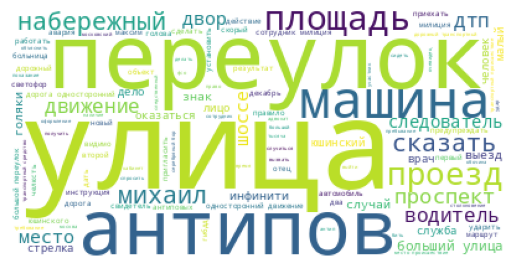

In [ ]:
from wordcloud import WordCloud
wordcloud = WordCloud(background_color='white').generate(' '.join(topic_model.get_representative_docs(topic=1)))
plt.figure()
plt.imshow(wordcloud)
plt.axis('off')
plt.show();

### Репрезентация тем (KeyBERT)

Библиотека BERTopic предлагает [различные варианты повышения интерпретируемости тем](https://maartengr.github.io/BERTopic/getting_started/representation/representation.html) (начиная от алгоритма KeyBERT и заканчивая суммаризацией с использованием ChatGPT). Давайте для примера рассмотрим классику - [KeyBERT](https://github.com/MaartenGr/KeyBERT).

Сначала давайте посмотрим на KeyBERT вне BERTopic (потому что его можно использовать не только для тематического моделирования). Это алгоритм извлечения ключевых слов (или n-грамм) из документов, основанный на использовании SentenceBERT, представленный в 2019 году.

In [ ]:
! pip install keybert -q

В качестве модели для получения эмбеддингов документов можем использовать модели Sentence Transformers, Spacy или Gensim.

In [ ]:
from keybert import KeyBERT
kw_model = KeyBERT(model='paraphrase-multilingual-MiniLM-L12-v2')

Извлечем ключевые слова (и словосочетания) из некоторого документа.

In [ ]:
doc = """
BERT обучается одновременно на двух задачах — предсказания следующего предложения (англ. next sentence prediction) и генерации пропущенного токена (англ. masked language modeling). На вход BERT подаются токенизированные пары предложений, в которых некоторые токены скрыты (см. рис. 2). Таким образом, благодаря маскированию токенов, сеть обучается глубокому двунаправленному представлению языка, учится понимать контекст предложения. Задача же предсказания следующего предложения есть задача бинарной классификации — является ли второе предложение продолжением первого. Благодаря ей сеть можно обучить различать наличие связи между предложениями в тексте.
"""
keywords = kw_model.extract_keywords(doc, highlight=True, keyphrase_ngram_range=(1,2), top_n=8)

BERT обучается на двух задачах предсказания следующего предложения англ next sentence prediction пропущенного 
токена англ masked language modeling вход BERT подаются токенизированные пары предложений которых некоторые токены 
скрыты см рис Таким образом благодаря маскированию токенов сеть обучается глубокому представлению языка понимать 
контекст предложения Задача же предсказания следующего предложения есть задача бинарной классификации является ли 
второе предложение продолжением первого Благодаря ей сеть можно обучить различать наличие связи между предложениями
тексте

In [ ]:
keywords

[('языка учится', 0.5535),
 ('language modeling', 0.5281),
 ('sentence prediction', 0.5238),
 ('bert обучается', 0.5094),
 ('обучается одновременно', 0.5086),
 ('учится понимать', 0.5036),
 ('представлению языка', 0.4953),
 ('обучается глубокому', 0.4908)]

Теперь давайте применим эту технику к тематическому моделированию (будем искать ключевые слова в документе, который получен конкатенацией всех документов темы).

In [ ]:
from bertopic.representation import KeyBERTInspired

In [ ]:
topic_model3 = BERTopic(embedding_model='distiluse-base-multilingual-cased-v1', n_gram_range=(1,3), top_n_words=2, calculate_probabilities=True,
                        representation_model=KeyBERTInspired())

In [ ]:
topics, probs = topic_model3.fit_transform(docs)

In [ ]:
topic_model3.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,700,-1_российский_россия,"[российский, россия]",[верить ребёнок последний верить управлять взр...
1,0,240,0_олимпийский игра_олимпийский,"[олимпийский игра, олимпийский]",[итог пройти олимпиада российский спортсмен от...
2,1,82,1_великий отечественный война_памятник,"[великий отечественный война, памятник]",[тема охрана культурный наследие столица после...
3,2,74,2_медицинский_медицинский помощь,"[медицинский, медицинский помощь]",[имя ассоциироваться легендарный хирург дебейк...
4,3,60,3_милиция_безопасность дорожный движение,"[милиция, безопасность дорожный движение]",[история живой щит мкад задержание автомобиль ...
5,4,60,4_право ребёнок_ребёнок,"[право ребёнок, ребёнок]",[весна надежда ребёнок родиться конец закончит...
6,5,53,5_осудить_судебный пристав,"[осудить, судебный пристав]",[условие бюджетный дефицит государство пытатьс...
7,6,50,6_александр борисович_театр,"[александр борисович, театр]",[игорь игорёк золото последний прозвище смешно...
8,7,49,7_усыновить_право ребёнок,"[усыновить, право ребёнок]",[семилетний мальчик иван скоробогатов погибнут...
9,8,46,8_террорист смертник_террористический,"[террорист смертник, террористический]",[прогреметь взрыв московский подземка общий че...


### Сохранение и загрузка моделей

Сохранить модель - значит запомнить метаданные модели и эмбеддинги документах в малой размерности.

По умолчанию при сохранении тематической модели BERTopic сохраняется модель для получения эмбеддингов (это влияет на вес модели).

In [ ]:
topic_model3.save('topic_model')

In [ ]:
topic_model4 = BERTopic()
topic_model4 = topic_model4.load('topic_model')

In [ ]:
topic_model4.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,700,-1_российский_россия,"[российский, россия]",[верить ребёнок последний верить управлять взр...
1,0,240,0_олимпийский игра_олимпийский,"[олимпийский игра, олимпийский]",[итог пройти олимпиада российский спортсмен от...
2,1,82,1_великий отечественный война_памятник,"[великий отечественный война, памятник]",[тема охрана культурный наследие столица после...
3,2,74,2_медицинский_медицинский помощь,"[медицинский, медицинский помощь]",[имя ассоциироваться легендарный хирург дебейк...
4,3,60,3_милиция_безопасность дорожный движение,"[милиция, безопасность дорожный движение]",[история живой щит мкад задержание автомобиль ...
5,4,60,4_право ребёнок_ребёнок,"[право ребёнок, ребёнок]",[весна надежда ребёнок родиться конец закончит...
6,5,53,5_осудить_судебный пристав,"[осудить, судебный пристав]",[условие бюджетный дефицит государство пытатьс...
7,6,50,6_александр борисович_театр,"[александр борисович, театр]",[игорь игорёк золото последний прозвище смешно...
8,7,49,7_усыновить_право ребёнок,"[усыновить, право ребёнок]",[семилетний мальчик иван скоробогатов погибнут...
9,8,46,8_террорист смертник_террористический,"[террорист смертник, террористический]",[прогреметь взрыв московский подземка общий че...


In [ ]:
topic_model4.transform(['Футбольчик!'])

([0],
 array([[9.63772292e-01, 1.18069695e-03, 9.71837049e-04, 8.87899501e-04,
         1.10456611e-03, 9.50797729e-04, 1.08956591e-03, 1.01511118e-03,
         9.12731471e-04, 1.21572932e-03, 1.07662732e-03, 9.63192730e-04,
         9.07914509e-04, 1.13406691e-03, 1.04034347e-03, 8.82081960e-04,
         9.38682895e-04, 8.82546787e-04, 1.09683612e-03, 8.92144351e-04,
         9.89364396e-04, 1.01334506e-03, 1.02287910e-03, 9.96710047e-04,
         1.07628788e-03, 9.81830354e-04, 1.01646070e-03, 9.66676528e-04,
         9.19266370e-04, 9.34800216e-04, 1.06934406e-03, 1.02966339e-03,
         1.03260604e-03, 1.00467161e-03, 9.60658595e-04, 9.18447281e-04,
         1.15132321e-03]]))

## Последнее слово Гуненкова

Дорогой (или дорогая) коллега, если ты сейчас читаешь этот текст, это значит, что мы с тобой завершили изучение дисциплины "Обработка естественного языка". Не буду спорить - углубляться можно до бесконечности. Однако курс преследовал две цели:
- познакомить вас с инструментами для решения самых разных задач NLP;
- объяснить принципы постановки задач и функционирования алгоритмов.

В соответствии с календарным планом, тебе предоставляется возможность в течение месяца сдавать лабораторные работы, практические задания и расчетно-графическую работу. И конечно же готовиться к экзамену!

Понимаю, что не каждый из нас будет профессионально заниматься датасайентсом после выпуска из университета. Тем не менее, надеюсь, что рассмотренный материал не оставил тебя равнодушным. Эти 19.5 часов теоретического материала и десятки часов на выполнение лабораторных и практических работ - часть уникальной программы обучения, доступной только на твоем направлении.

Мы все учимся, поэтому буду рад увидеть любую обратную связь от тебя по дисциплине. Оставить ее ты можешь [в этой форме](https://forms.gle/5CFJGopBbuQFfqeZA). Никто кроме нас с тобой не прочитает, поэтому можешь написать то, чего лично точно никогда не скажешь. Все анонимно.

Желаю тебе не разочароваться в выбранном пути и дойти до конца. Успехов на экзамене! Пусть все твои цели достигаются, в том числе при помощи методов обработки естественного языка.

*С уважением, Гуненков М. Ю.*